# TP3 — IA de classification météo à partir des capteurs de la carte (Meteostat)
**ETRS923 — IA et Objets Connectés · USMB Master ESET** · Auteur : Aris Trache

**Objectif** : classer la météo du moment à partir de ce que mesure **réellement** la carte X-NUCLEO-IKS01A3 :
température, humidité, pression. On entraîne ici le modèle (Python / TensorFlow) sur des données réelles Meteostat,
puis on l'exporte vers le **Cloud** (ONNX → MATLAB / ThingSpeak) et vers l'**Edge** (TFLite int8 → X-CUBE-AI → STM32N6).

**Règle d'or** : aucune entrée que la carte ne peut pas produire. Pas de vent (pas d'anémomètre), pas de nébulosité,
pas de précipitations mesurées. C'est la contrainte qui rend le projet honnête et déployable.

| Étape | Ce qu'on étudie | Question du TP |
|---|---|---|
| 1 | Données réelles (6 stations, 2017-2025) | 1.a |
| 2 | Features calculables sur la carte | 1.a |
| 3 | **Nombre de classes** ↔ précision | 1.b |
| 4 | Historique nécessaire (instantané / 6 h / 24 h / heure) | 1.b |
| 5 | **Taille du modèle** ↔ précision (+ référence non neuronale) | 1.b |
| 6 | Démarrage à froid de la carte | déploiement |
| 7 | Modèle final + hyperparamètres justifiés | 1.b |
| 8 | Export Keras / ONNX / TFLite int8 + en-tête C | 2.a, 3.a |

> Colab : *Exécution → Tout exécuter* (un CPU suffit : les modèles font ~1 000 paramètres). Durée ≈ 10 min.

## 0. Préparation

In [1]:
import os, sys, json, time
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.exists("ia-meteo-edge"):
        !git clone -q https://github.com/Aris-Trache/ia-meteo-edge.git
    !pip -q install tf2onnx onnxruntime
    ROOT = "ia-meteo-edge"
else:
    ROOT = ".."
sys.path.insert(0, os.path.join(ROOT, "notebooks"))

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt, tensorflow as tf
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             confusion_matrix, classification_report)
from sklearn.ensemble import HistGradientBoostingClassifier
import meteo_features as mf

DATA = os.path.join(ROOT, "data", "meteostat_alpes_2017_2025.csv.gz")
OUT = "resultats_tp3"; os.makedirs(OUT, exist_ok=True)
MODELS = os.path.join(ROOT, "models"); os.makedirs(MODELS, exist_ok=True)
print("TensorFlow", tf.__version__)

I0000 00:00:1794399821.104033   18268 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794399822.475856   18268 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


## 1. Données réelles Meteostat
6 stations du même climat (Alpes du Nord / vallée du Rhône), **dont Chambéry / Aix-les-Bains, à 3 km du campus**.
Plusieurs stations = plus d'exemples des classes rares (neige, orage, brouillard) et un modèle qui ne « récite » pas une station.

Récupération : `data/fetch_meteostat.py` (fichier fourni dans le dépôt pour la reproductibilité).
Licence des données : **CC BY-NC 4.0, Meteostat** (sources : Météo-France, MeteoSuisse…).

**Nettoyage** (dans `load_dataset`) : valeurs physiquement impossibles mises à NaN (ex. humidité 255 %),
trous horaires rendus explicites pour qu'une tendance ne soit jamais calculée entre deux heures non consécutives,
sauts aberrants supprimés (ex. pression qui varie de 13 hPa en 1 h = erreur de mesure, pas de la météo).

In [2]:
D = mf.load_dataset(DATA)
print(f"{len(D):,} heures exploitables")
display(D.groupby("station").size().rename("heures").to_frame().T)

# Decoupage TEMPOREL : on predit le futur a partir du passe (pas de melange aleatoire,
# sinon deux heures voisines quasi identiques se retrouvent en train ET en test).
yr = D.index.year
TRAIN, VAL, TEST = D[yr <= 2022], D[yr == 2023], D[yr >= 2024]
print(f"train 2017-2022 : {len(TRAIN):,} | validation 2023 : {len(VAL):,} | test 2024-2025 : {len(TEST):,}")

359,637 heures exploitables


station,06700,07481,07486,07491,07577,LFLP0
heures,65303,65198,65635,65830,63693,33978


train 2017-2022 : 215,539 | validation 2023 : 52,552 | test 2024-2025 : 91,546


## 2. Features : uniquement ce que la carte sait calculer
| Feature | Calcul sur la carte | Intérêt météo |
|---|---|---|
| `temp`, `rhum` | HTS221 | état de la masse d'air |
| `pres` | LPS22HH **ramenée au niveau de la mer** (altitude connue) | anticyclone / dépression |
| `spread` = T − T_rosée | formule de Magnus | ≈ 0 → air saturé (brouillard, pluie) |
| `dp1`, `dp3`, `dp6` | différence avec la pression d'il y a 1/3/6 h | **le principe du baromètre** : la pression qui chute annonce la dégradation |
| `dt1`, `dt3`, `drh1`, `drh3` | idem pour T et HR | front, averse (chute brutale de T) |
| `rhmax6`, `rhmin6`, `sp_mean6` | min/max/moyenne glissants 6 h | persistance de l'humidité |

**Piège évité — la pression** : le LPS22HH mesure la pression **absolue** (~985 hPa à 240 m), Meteostat donne la pression
**réduite au niveau de la mer** (~1013 hPa). Sans conversion sur la carte, le modèle verrait une « tempête » permanente.

In [3]:
print("Exemple de conversion : 985.0 hPa mesures a 240 m, 15 degC ->",
      round(float(mf.sea_level_pressure(985.0, 15.0, 240.0)), 1), "hPa au niveau de la mer")
display(D[mf.FEATURES_FINAL].describe().T[["mean", "std", "min", "max"]].round(2))

Exemple de conversion : 985.0 hPa mesures a 240 m, 15 degC -> 1013.4 hPa au niveau de la mer


,mean,std,min,max
temp,13.08,8.31,-11.7,40.00
rhum,72.90,18.93,1.0,100.00
pres,1017.61,7.83,979.8,1044.20
spread,5.48,4.85,-0.0,61.19
dp3,0.00,1.30,-8.0,8.00
dp1,0.00,0.55,-4.0,4.00
dt3,-0.01,2.95,-15.0,15.00
drh3,0.05,12.01,-60.0,60.00
dp6,-0.00,2.21,-15.6,14.70
dt1,-0.00,1.25,-19.0,29.00


### Outil commun d'entraînement / évaluation
- **Normalisation** (moyenne / écart-type du *train* uniquement) : faite **hors du modèle** et réimplémentée en C,
  pour garder une quantification int8 précise (sinon la pression ~1013 hPa écraserait la résolution des tendances ~±2 hPa).
- **Poids de classes** = (fréquence)^-0,5 : compromis entre ignorer les classes rares et les sur-prédire.
- **Métriques** : *accuracy* seule est trompeuse quand les classes sont déséquilibrées (dire toujours « nuageux » donne déjà ~50 %).
  On regarde donc aussi l'**accuracy équilibrée** (moyenne des rappels par classe) et le **F1 macro**, et on compare à la
  **référence « classe majoritaire »**.

In [4]:
def xy(d, feats, K):
    return d[feats].to_numpy("float32"), d["coco"].map(mf.GROUPINGS[K]["map"]).to_numpy("int64")

def train_eval(K, feats, hidden=(32, 16), cold_frac=0.0, seed=0, epochs=60, verbose=False, return_model=False):
    n = len(mf.GROUPINGS[K]["names"])
    tr = TRAIN.copy()
    if cold_frac > 0:   # augmentation "demarrage a froid" (voir etape 6)
        idx = np.random.default_rng(seed).random(len(tr)) < cold_frac
        tr.loc[idx, feats] = mf.cold_start(tr.loc[idx])[feats]
    Xtr, ytr = xy(tr, feats, K); Xva, yva = xy(VAL, feats, K); Xte, yte = xy(TEST, feats, K)
    mu = TRAIN[feats].to_numpy("float32").mean(0); sd = TRAIN[feats].to_numpy("float32").std(0) + 1e-6
    cnt = np.bincount(ytr, minlength=n); w = (cnt.sum() / (n * np.maximum(cnt, 1))) ** 0.5
    tf.keras.utils.set_random_seed(seed)
    layers = [tf.keras.Input((len(feats),), name="features")]
    layers += [tf.keras.layers.Dense(h, activation="relu") for h in hidden]
    layers += [tf.keras.layers.Dense(n, activation="softmax", name="classe")]
    m = tf.keras.Sequential(layers)
    m.compile(optimizer=tf.keras.optimizers.Adam(2e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    t0 = time.time()
    h = m.fit((Xtr - mu) / sd, ytr, validation_data=((Xva - mu) / sd, yva), epochs=epochs, batch_size=512,
              class_weight={i: float(w[i]) for i in range(n)}, verbose=verbose,
              callbacks=[tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)])
    p = m.predict((Xte - mu) / sd, verbose=0).argmax(1)
    maj = np.bincount(ytr).argmax()
    r = dict(K=K, classes=n, n_entrees=len(feats), couches=str(hidden), params=m.count_params(),
             accuracy=accuracy_score(yte, p), acc_equilibree=balanced_accuracy_score(yte, p),
             f1_macro=f1_score(yte, p, average="macro"), ref_majoritaire=accuracy_score(yte, np.full_like(yte, maj)),
             epochs=len(h.history["loss"]), temps_s=round(time.time() - t0, 1))
    if return_model:
        return r, m, mu, sd, h.history
    return r

def show(rows, name):
    df = pd.DataFrame(rows); df.to_csv(f"{OUT}/{name}.csv", index=False)
    return df.style.format({c: "{:.3f}" for c in ("accuracy", "acc_equilibree", "f1_macro", "ref_majoritaire")})

## 3. Étude n°1 — Nombre de classes (question 1.b)
Mêmes features (instantané + tendances 3 h), même réseau 32-16. Seul le **découpage des classes** change :

| Découpage | Classes |
|---|---|
| K2 | Sec / Précipitations-phénomène |
| K3 | Dégagé / Nuageux-Couvert / Précipitations |
| K5 | + Brouillard, Neige-Mixte (pluie et orage fusionnés) |
| K6 | + Orage séparé |
| K10 | liste du sujet : 4 niveaux de ciel, brouillard, pluie, averses, neige, pluie+neige, orage (*vent fort exclu : non mesurable*) |

In [5]:
FEAT_3H = mf.BASE + mf.TREND3
rows = [train_eval(K, FEAT_3H) for K in ["K2", "K3", "K5", "K6", "K10"]]
res_classes = pd.DataFrame(rows)
show(rows, "etude1_nb_classes")

,K,classes,n_entrees,couches,params,accuracy,acc_equilibree,f1_macro,ref_majoritaire,epochs,temps_s
0,K2,2,8,"(32, 16)",850,0.788,0.767,0.720,0.799,8,8.400000
1,K3,3,8,"(32, 16)",867,0.609,0.617,0.592,0.553,21,19.300000
2,K5,5,8,"(32, 16)",901,0.549,0.578,0.465,0.503,46,41.700000
3,K6,6,8,"(32, 16)",918,0.517,0.574,0.397,0.503,33,31.600000
4,K10,10,8,"(32, 16)",986,0.366,0.387,0.275,0.285,56,53.600000


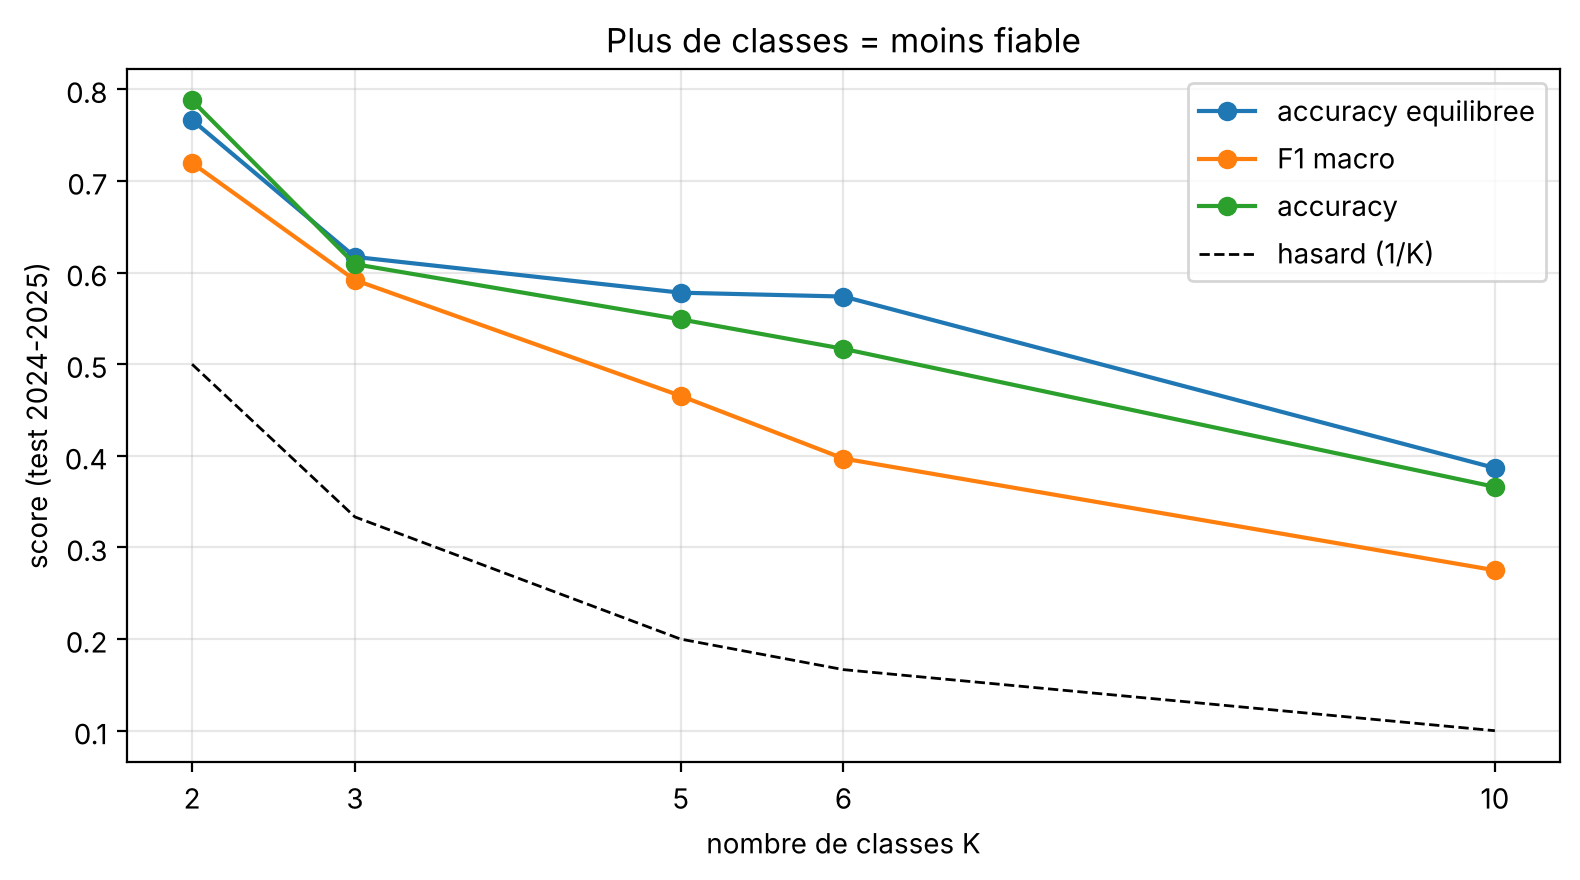

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = res_classes["classes"]
for col, lab in [("acc_equilibree", "accuracy equilibree"), ("f1_macro", "F1 macro"), ("accuracy", "accuracy")]:
    ax.plot(x, res_classes[col], "o-", label=lab)
ax.plot(x, 1 / x, "k--", lw=1, label="hasard (1/K)")
ax.set_xlabel("nombre de classes K"); ax.set_ylabel("score (test 2024-2025)"); ax.set_xticks(x)
ax.set_title("Plus de classes = moins fiable"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT}/etude1_nb_classes.png", dpi=150); plt.show()

**Lecture** : avec 3 capteurs, on sait bien distinguer « sec / précipitations » et correctement « dégagé / nuageux / précipitations ».
Au-delà, les classes fines (*clair* vs *peu nuageux*, *pluie* vs *averse*) se ressemblent trop du point de vue T/HR/P :
le modèle reste au-dessus du hasard mais devient peu fiable classe par classe (F1 macro qui chute).
La taille du modèle, elle, ne bouge presque pas (seule la dernière couche grandit : 17 paramètres par classe).

## 4. Étude n°2 — Quel historique ? (question 1.b)
Plus d'historique = plus d'information, mais la carte doit **attendre** d'avoir cet historique avant de prédire, et le stocker.

In [7]:
SETS = {
    "instantane (4)": mf.BASE,
    "tendances 3 h (8)": mf.BASE + mf.TREND3,
    "historique 6 h (14) <- retenu": mf.FEATURES_FINAL,
    "historique 24 h (17)": mf.FEATURES_FINAL + mf.HIST24,
    "6 h + heure/saison (18)": mf.FEATURES_FINAL + mf.TIME,
}
rows = []
for K in ["K3", "K5"]:
    for name, feats in SETS.items():
        r = train_eval(K, feats); r["features"] = name; rows.append(r)
show(rows, "etude2_historique")

,K,classes,n_entrees,couches,params,accuracy,acc_equilibree,f1_macro,ref_majoritaire,epochs,temps_s,features
0,K3,3,4,"(32, 16)",739,0.589,0.575,0.562,0.553,8,9.900000,instantane (4)
1,K3,3,8,"(32, 16)",867,0.609,0.617,0.592,0.553,21,19.900000,tendances 3 h (8)
2,K3,3,14,"(32, 16)",1059,0.628,0.636,0.612,0.553,48,42.400000,historique 6 h (14) <- retenu
3,K3,3,17,"(32, 16)",1155,0.637,0.644,0.620,0.553,38,36.200000,historique 24 h (17)
4,K3,3,18,"(32, 16)",1187,0.640,0.659,0.627,0.553,27,26.100000,6 h + heure/saison (18)
5,K5,5,4,"(32, 16)",773,0.522,0.537,0.431,0.503,15,15.600000,instantane (4)
6,K5,5,8,"(32, 16)",901,0.549,0.578,0.465,0.503,46,40.000000,tendances 3 h (8)
7,K5,5,14,"(32, 16)",1093,0.567,0.597,0.480,0.503,46,40.500000,historique 6 h (14) <- retenu
8,K5,5,17,"(32, 16)",1189,0.573,0.608,0.483,0.503,22,20.500000,historique 24 h (17)
9,K5,5,18,"(32, 16)",1221,0.581,0.604,0.485,0.503,48,40.100000,6 h + heure/saison (18)


**Choix : historique 6 h (14 entrées)**
- Les tendances apportent nettement plus que l'instantané (principe du baromètre confirmé par les données).
- Passer de 6 h à 24 h ne rapporte qu'environ 1 point, mais oblige la carte à attendre 24 h avant sa première prédiction complète.
- L'heure et la saison aident un peu (~1-2 points), mais demandent une horloge synchronisée (NTP via le réseau du TP2).
  C'est une **perspective** : le modèle retenu fonctionne dès la mise sous tension, sans dépendre du réseau.

## 5. Étude n°3 — Taille du modèle (question 1.b)
On fixe K3 et les 14 entrées, on fait varier l'architecture. On ajoute une **référence non neuronale puissante**
(gradient boosting, ~centaines d'arbres) pour savoir si un modèle bien plus gros pourrait faire mieux.

In [8]:
rows = [train_eval("K3", mf.FEATURES_FINAL, hidden=hd) for hd in [(8,), (16,), (32, 16), (64, 32), (128, 64, 32)]]
Xtr, ytr = xy(TRAIN, mf.FEATURES_FINAL, "K3"); Xte, yte = xy(TEST, mf.FEATURES_FINAL, "K3")
gb = HistGradientBoostingClassifier(max_iter=300, class_weight="balanced", random_state=0).fit(Xtr, ytr)
p = gb.predict(Xte)
rows.append(dict(K="K3", couches="gradient boosting (reference)", params=np.nan, accuracy=accuracy_score(yte, p),
                 acc_equilibree=balanced_accuracy_score(yte, p), f1_macro=f1_score(yte, p, average="macro")))
res_taille = pd.DataFrame(rows)
show(rows, "etude3_taille")

,K,classes,n_entrees,couches,params,accuracy,acc_equilibree,f1_macro,ref_majoritaire,epochs,temps_s
0,K3,3.000000,14.000000,"(8,)",147.000000,0.602,0.613,0.586,0.553,15.000000,15.600000
1,K3,3.000000,14.000000,"(16,)",291.000000,0.613,0.627,0.598,0.553,60.000000,46.000000
2,K3,3.000000,14.000000,"(32, 16)",1059.000000,0.628,0.636,0.612,0.553,48.000000,43.000000
3,K3,3.000000,14.000000,"(64, 32)",3139.000000,0.631,0.639,0.615,0.553,25.000000,24.000000
4,K3,3.000000,14.000000,"(128, 64, 32)",12355.000000,0.630,0.638,0.614,0.553,24.000000,27.000000
5,K3,nan,nan,gradient boosting (reference),nan,0.579,0.639,0.575,nan,nan,nan


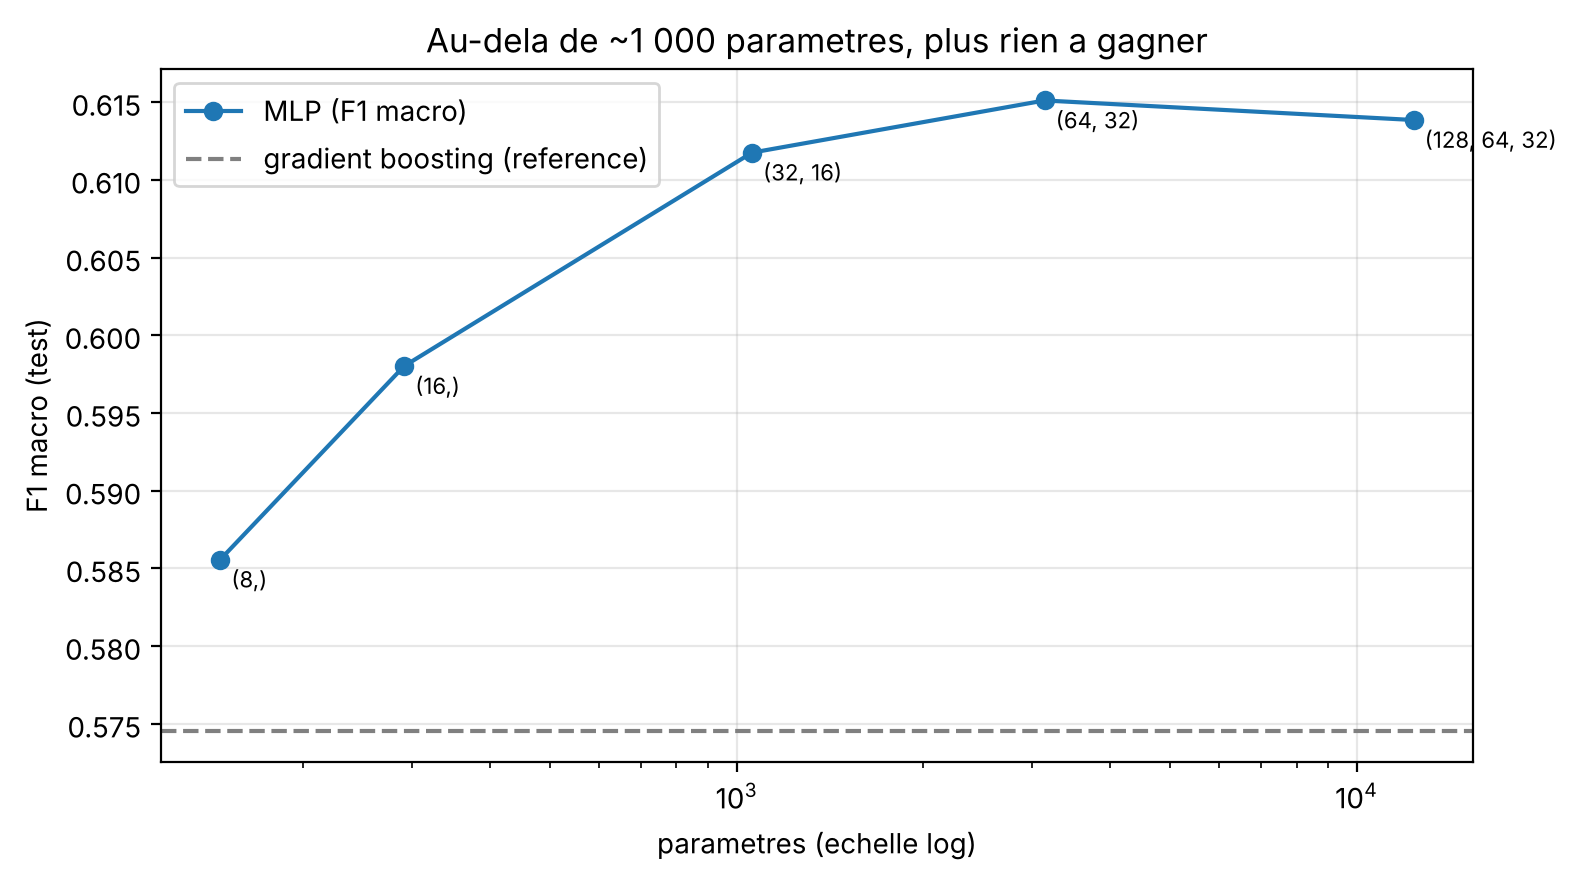

In [9]:
r = res_taille.dropna(subset=["params"])
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.semilogx(r["params"], r["f1_macro"], "o-", label="MLP (F1 macro)")
ax.axhline(res_taille.iloc[-1]["f1_macro"], color="gray", ls="--", label="gradient boosting (reference)")
for _, row in r.iterrows():
    ax.annotate(row["couches"], (row["params"], row["f1_macro"]), fontsize=8, xytext=(4, -10), textcoords="offset points")
ax.set_xlabel("parametres (echelle log)"); ax.set_ylabel("F1 macro (test)"); ax.grid(alpha=.3); ax.legend()
ax.set_title("Au-dela de ~1 000 parametres, plus rien a gagner")
plt.tight_layout(); plt.savefig(f"{OUT}/etude3_taille.png", dpi=150); plt.show()

**Lecture — le résultat le plus important du TP** : un réseau de ~1 000 paramètres fait aussi bien qu'un réseau 13× plus gros
**et** qu'un gradient boosting. La limite vient de **l'information contenue dans 3 capteurs**, pas du modèle.
Pour l'embarqué, c'est la meilleure nouvelle possible : le petit modèle est le bon (sobriété : mémoire, calcul, énergie — critère P_TEDS).

## 6. Étude n°4 — Démarrage à froid
À la mise sous tension, la carte n'a **aucun historique** : les tendances sont inconnues. Convention (identique en C) :
tendances = 0 et min/max/moyenne 6 h = valeur courante. On compare un modèle entraîné normalement et un modèle qui a vu
15 % d'exemples « sans historique » pendant l'entraînement.

In [10]:
def eval_cold(m, mu, sd, K):
    Xc = mf.cold_start(TEST)[mf.FEATURES_FINAL].to_numpy("float32"); _, yte = xy(TEST, mf.FEATURES_FINAL, K)
    p = m.predict((Xc - mu) / sd, verbose=0).argmax(1)
    return balanced_accuracy_score(yte, p), f1_macro_(yte, p)
f1_macro_ = lambda y, p: f1_score(y, p, average="macro")
rows = []
for frac in [0.0, 0.15, 0.30]:
    r, m, mu, sd, _ = train_eval("K3", mf.FEATURES_FINAL, cold_frac=frac, return_model=True)
    ba, f1 = eval_cold(m, mu, sd, "K3")
    rows.append(dict(part_sans_historique=frac, f1_macro_avec_historique=r["f1_macro"], acc_eq_avec_historique=r["acc_equilibree"],
                     f1_macro_demarrage_froid=f1, acc_eq_demarrage_froid=ba))
display(pd.DataFrame(rows).round(3)); pd.DataFrame(rows).to_csv(f"{OUT}/etude4_demarrage_froid.csv", index=False)

,part_sans_historique,f1_macro_avec_historique,acc_eq_avec_historique,f1_macro_demarrage_froid,acc_eq_demarrage_froid
0,0.00,0.612,0.636,0.546,0.534
1,0.15,0.606,0.633,0.564,0.566
2,0.30,0.605,0.632,0.557,0.570


**Choix : 15 %**. La précision avec historique est inchangée, et la carte donne une prédiction utile dès la première mesure.
La qualité s'améliore ensuite toute seule à mesure que l'historique se remplit (6 h).

## 7. Modèle final
| Choix | Valeur | Justification |
|---|---|---|
| Classes | **K3** : Dégagé / Nuageux-Couvert / Précipitations | meilleur compromis fiabilité / information (étude 1) |
| Entrées | **14** (instantané + tendances + historique 6 h) | étude 2 ; aucune horloge requise |
| Réseau | **14 → 32 → 16 → 3**, ReLU, softmax | plateau atteint (étude 3) ; ReLU = `max(0,x)`, le moins coûteux sur MCU |
| Optimiseur | Adam, lr = 2·10⁻³, batch 512 | convergence rapide et stable (TP1) ; batch 512 pour 200 000 exemples |
| Arrêt | EarlyStopping patience 5 sur la *val loss* (2023) | évite le sur-apprentissage, garde les meilleurs poids |
| Coût | entropie croisée + poids de classes (fréq.)^-0,5 | classes déséquilibrées (17 % de précipitations) |
| Robustesse | 15 % d'exemples sans historique | démarrage à froid (étude 4) |

On entraîne **3 fois** (graines différentes) pour mesurer le bruit, et on garde le modèle de graine 0 pour l'export.

In [11]:
K = "K3"; NAMES = mf.GROUPINGS[K]["names"]
runs = [train_eval(K, mf.FEATURES_FINAL, cold_frac=0.15, seed=s, return_model=True) for s in (0, 1, 2)]
bruit = pd.DataFrame([r[0] for r in runs])[["accuracy", "acc_equilibree", "f1_macro"]]
display(bruit.describe().loc[["mean", "std"]].round(3))
res_final, model, MU, SD, hist = runs[0]
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in res_final.items()})

,accuracy,acc_equilibree,f1_macro
mean,0.619,0.635,0.604
std,0.001,0.002,0.002


{'K': 'K3', 'classes': 3, 'n_entrees': 14, 'couches': '(32, 16)', 'params': 1059, 'accuracy': 0.62, 'acc_equilibree': 0.633, 'f1_macro': 0.606, 'ref_majoritaire': 0.553, 'epochs': 23, 'temps_s': 24.7}


                 precision    recall  f1-score   support

         Degage      0.596     0.590     0.593     27060
Nuageux-Couvert      0.694     0.617     0.653     50623
 Precipitations      0.486     0.692     0.571     13863

       accuracy                          0.620     91546
      macro avg      0.592     0.633     0.606     91546
   weighted avg      0.633     0.620     0.623     91546



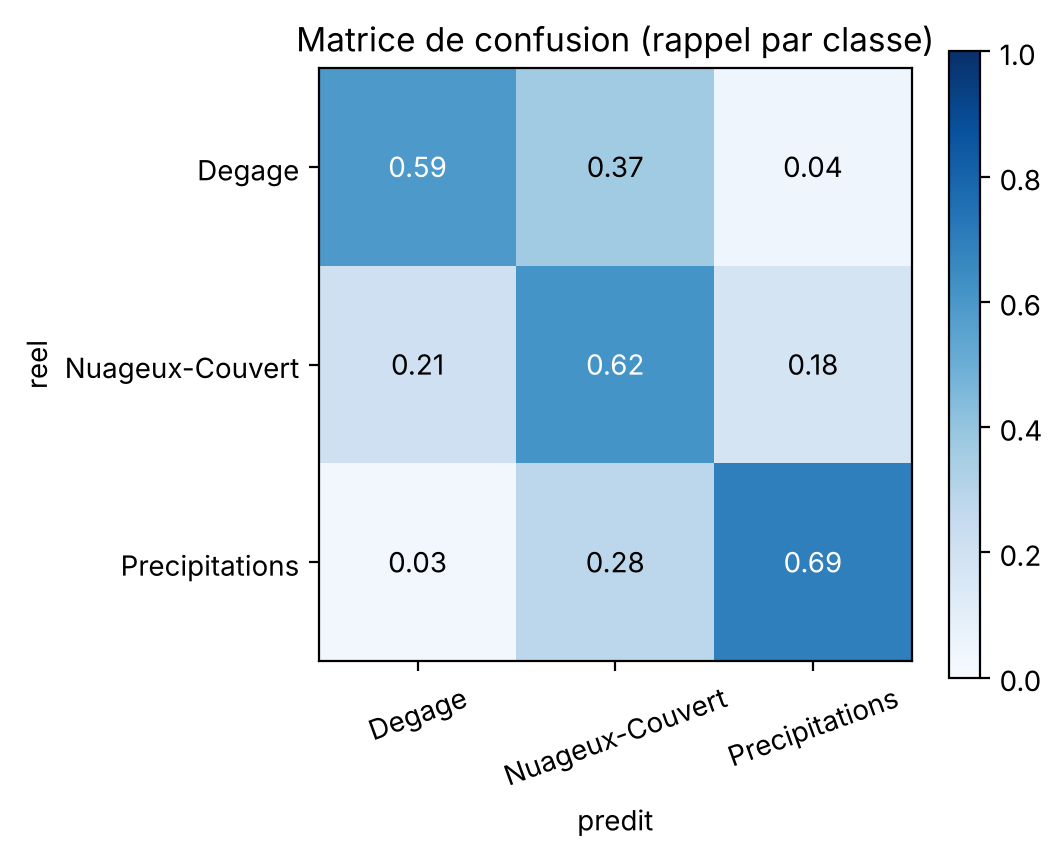

Chambery seule : accuracy 0.672 | equilibree 0.704 | F1 macro 0.622


In [12]:
Xte, yte = xy(TEST, mf.FEATURES_FINAL, K)
proba = model.predict((Xte - MU) / SD, verbose=0); p = proba.argmax(1)
print(classification_report(yte, p, target_names=NAMES, digits=3))
cm = confusion_matrix(yte, p, normalize="true")
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(NAMES)), NAMES, rotation=20); ax.set_yticks(range(len(NAMES)), NAMES)
for i in range(len(NAMES)):
    for j in range(len(NAMES)):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", color="white" if cm[i, j] > .5 else "black")
ax.set_xlabel("predit"); ax.set_ylabel("reel"); ax.set_title("Matrice de confusion (rappel par classe)")
plt.colorbar(im); plt.tight_layout(); plt.savefig(f"{OUT}/confusion_finale.png", dpi=150); plt.show()

# Verification sur la station du projet uniquement (Chambery / Aix)
ch = TEST[TEST.station == "07491"]; Xc, yc = xy(ch, mf.FEATURES_FINAL, K)
pc = model.predict((Xc - MU) / SD, verbose=0).argmax(1)
print(f"Chambery seule : accuracy {accuracy_score(yc, pc):.3f} | equilibree {balanced_accuracy_score(yc, pc):.3f} | F1 macro {f1_score(yc, pc, average='macro'):.3f}")

## 8. Export : Keras, ONNX (Cloud), TFLite int8 (Edge), en-tête C
- **ONNX** : format neutre et standardisé, lu par MATLAB (`importNetworkFromONNX`) pour l'inférence ThingSpeak (TP3.2).
- **TFLite int8** : poids et calculs sur 8 bits, pour X-CUBE-AI et le NPU du STM32N6 (TP3.3). Entrée et sortie restent en float.
- **`meteo_model_params.h`** : moyenne et écart-type de normalisation, ordre des features, noms des classes.
  **Une seule source de vérité** générée automatiquement, pour éviter une recopie à la main entre Python et C.

In [13]:
tag = "meteo_k3_mlp"
model.save(f"{MODELS}/{tag}.keras")

# --- ONNX (via tf.function : contourne l'incompatibilite tf2onnx / Keras 3 de from_keras)
import tf2onnx, onnxruntime as ort
spec = (tf.TensorSpec((None, len(mf.FEATURES_FINAL)), tf.float32, name="features"),)
@tf.function(input_signature=spec)
def _infer(x):
    return {"probabilites": model(x)}
onnx_model, _ = tf2onnx.convert.from_function(_infer, input_signature=spec, opset=13)
open(f"{MODELS}/{tag}.onnx", "wb").write(onnx_model.SerializeToString())
sess = ort.InferenceSession(onnx_model.SerializeToString())
Xn = ((Xte - MU) / SD).astype("float32")
p_onnx = sess.run(None, {"features": Xn[:2000]})[0]
print("ONNX : ecart max avec Keras =", float(np.abs(p_onnx - proba[:2000]).max()),
      "| decisions identiques :", bool((p_onnx.argmax(1) == p[:2000]).all()))

# --- TFLite int8 (calibration sur 2 000 exemples du train)
Xcal = ((TRAIN[mf.FEATURES_FINAL].to_numpy("float32") - MU) / SD)[::100][:2000]
conv = tf.lite.TFLiteConverter.from_keras_model(model)
conv.optimizations = [tf.lite.Optimize.DEFAULT]
conv.representative_dataset = lambda: ([x[None]] for x in Xcal)
conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
conv.inference_input_type = tf.float32; conv.inference_output_type = tf.float32
tfl = conv.convert(); open(f"{MODELS}/{tag}_int8.tflite", "wb").write(tfl)
itp = tf.lite.Interpreter(model_content=tfl); itp.allocate_tensors()
i_in, i_out = itp.get_input_details()[0]["index"], itp.get_output_details()[0]["index"]
p_q = []
for x in Xn[:5000]:
    itp.set_tensor(i_in, x[None]); itp.invoke(); p_q.append(itp.get_tensor(i_out)[0].argmax())
p_q = np.array(p_q)
print(f"TFLite int8 : {len(tfl)} octets | accuracy float {accuracy_score(yte[:5000], p[:5000]):.4f} "
      f"-> int8 {accuracy_score(yte[:5000], p_q):.4f} | decisions identiques a {np.mean(p_q == p[:5000])*100:.1f} %")

ONNX : ecart max avec Keras = 1.1920928955078125e-07 | decisions identiques : True
INFO:tensorflow:Assets written to: /tmp/tmpir32h18y/assets


INFO:tensorflow:Assets written to: /tmp/tmpir32h18y/assets


Saved artifact at '/tmp/tmpir32h18y'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 14), dtype=tf.float32, name='features')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  140001698147856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140001698141712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140001698142096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140001698136336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140001698139792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140001698138448: TensorSpec(shape=(), dtype=tf.resource, name=None)


/usr/local/lib/python3.13/site-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
fully_quantize: 0, inference_type: 6, input_inference_type: FLOAT32, output_inference_type: FLOAT32
/usr/local/lib/python3.13/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


TFLite int8 : 5360 octets | accuracy float 0.6022 -> int8 0.6002 | decisions identiques a 97.1 %


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


In [14]:
# --- Normalisation + metadonnees (JSON pour MATLAB, .h pour le C)
meta = {"features": mf.FEATURES_FINAL, "mean": MU.tolist(), "std": SD.tolist(), "classes": NAMES,
        "history_hours": mf.HISTORY_HOURS, "pressure": "niveau de la mer [hPa] (convertir la pression station)",
        "dew_point": "Magnus a=17.62 b=243.12", "cold_start": "tendances=0 ; min/max/moy 6h = valeur courante",
        "test_2024_2025": {k: float(res_final[k]) for k in ("accuracy", "acc_equilibree", "f1_macro")},
        "params": int(res_final["params"]), "tflite_int8_bytes": len(tfl)}
json.dump(meta, open(f"{MODELS}/{tag}_meta.json", "w"), indent=2)

def c_arr(v): return ", ".join(f"{x:.7g}f" for x in v)
h = [ "/* Genere automatiquement par notebooks/TP3_Meteostat_IA.ipynb -- NE PAS EDITER A LA MAIN */",
      "#ifndef METEO_MODEL_PARAMS_H", "#define METEO_MODEL_PARAMS_H", "",
      f"#define METEO_NB_FEATURES   {len(mf.FEATURES_FINAL)}",
      f"#define METEO_NB_CLASSES    {len(NAMES)}",
      f"#define METEO_HISTORY_HOURS {mf.HISTORY_HOURS}", "",
      "/* Ordre des entrees du modele */"]
h += [f"#define METEO_F_{f.upper():<9} {i}" for i, f in enumerate(mf.FEATURES_FINAL)]
h += ["", "/* Normalisation : x_norm = (x - mean) / std  (statistiques du jeu d'entrainement 2017-2022) */",
      f"static const float METEO_MEAN[METEO_NB_FEATURES] = {{ {c_arr(MU)} }};",
      f"static const float METEO_STD[METEO_NB_FEATURES]  = {{ {c_arr(SD)} }};", "",
      "static const char *const METEO_CLASS_NAMES[METEO_NB_CLASSES] = { " + ", ".join(f'"{n}"' for n in NAMES) + " };", "",
      "#endif /* METEO_MODEL_PARAMS_H */", ""]
open(f"{MODELS}/meteo_model_params.h", "w").write("\n".join(h))
print("\n".join(h[:14]), "...")
pd.DataFrame(hist).to_csv(f"{OUT}/historique_entrainement_final.csv", index=False)
print(os.listdir(MODELS))

/* Genere automatiquement par notebooks/TP3_Meteostat_IA.ipynb -- NE PAS EDITER A LA MAIN */
#ifndef METEO_MODEL_PARAMS_H
#define METEO_MODEL_PARAMS_H

#define METEO_NB_FEATURES   14
#define METEO_NB_CLASSES    3
#define METEO_HISTORY_HOURS 6

/* Ordre des entrees du modele */
#define METEO_F_TEMP      0
#define METEO_F_RHUM      1
#define METEO_F_PRES      2
#define METEO_F_SPREAD    3
#define METEO_F_DP3       4 ...
['meteo_k3_mlp_int8.tflite', 'meteo_model_params.h', 'meteo_k3_mlp_meta.json', 'meteo_k3_mlp.keras', 'meteo_k3_mlp.onnx']


In [15]:
# Vecteurs de test pour verifier le code C de la carte (meme entree -> meme sortie attendue)
vec = TEST.sample(8, random_state=1)
xv = vec[mf.FEATURES_FINAL].to_numpy("float32"); pv = model.predict((xv - MU) / SD, verbose=0)
tests = [{"features": xv[i].round(4).tolist(), "probabilites": pv[i].round(5).tolist(),
          "classe_attendue": NAMES[int(pv[i].argmax())], "coco_reel": int(vec.coco.iloc[i])} for i in range(len(vec))]
json.dump(tests, open(f"{MODELS}/{tag}_vecteurs_test.json", "w"), indent=1)
print(json.dumps(tests[0], indent=1))

{
 "features": [
  9.199999809265137,
  63.0,
  1012.7000122070312,
  6.684800148010254,
  1.399999976158142,
  0.699999988079071,
  -0.30000001192092896,
  2.0,
  3.4000000953674316,
  0.5,
  -4.0,
  67.0,
  60.0,
  6.771999835968018
 ],
 "probabilites": [
  0.2052299976348877,
  0.6914700269699097,
  0.1033099964261055
 ],
 "classe_attendue": "Nuageux-Couvert",
 "coco_reel": 3
}


In [16]:
try:   # telechargement automatique sous Colab
    import shutil
    from google.colab import files
    shutil.make_archive("resultats_tp3", "zip", OUT); files.download("resultats_tp3.zip")
    shutil.make_archive("modeles_tp3", "zip", MODELS); files.download("modeles_tp3.zip")
except ImportError:
    print("Hors Colab : resultats dans", OUT, "et modeles dans", MODELS)

Hors Colab : resultats dans resultats_tp3 et modeles dans ../models


## Conclusion
- **Données réelles** : 6 stations Meteostat, ~360 000 heures, découpage temporel strict (test = 2024-2025, jamais vu).
- **Nombre de classes** : la fiabilité chute avec K ; **K3** est le meilleur compromis pour 3 capteurs. K5 (avec brouillard et neige) reste possible, avec moins de fiabilité.
- **Taille** : ~1 000 paramètres suffisent, et un modèle 13× plus gros ou un gradient boosting ne font pas mieux. La limite est physique (3 capteurs), pas algorithmique.
- **Déploiement** : 14 entrées calculables sur la carte, historique 6 h, démarrage à froid géré, modèle int8 de quelques Ko.
- **Perspectives** : heure synchronisée par NTP (+1 à 2 points), capteur de luminosité (dégagé vs nuageux) ou pluviomètre, apprentissage continu dans le Cloud avec les données de la carte (boucle Cloud → Edge du TP3).